# Vitis Runs 5 Runs with 5 rounds of Feedback

In [49]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats
import seaborn as sns
import plotly.express as px


In [50]:
df_norag = pd.read_csv('5x5Data/vitis_5x5_norag.csv')
# df_rag = pd.read_csv('5x5Data/vitis_5x5_norag.csv')

df_norag = df_norag.sort_values(by=['model', 'run', 'kernel', 'attempt'])

df_norag['latency'] = pd.to_numeric(df_norag['latency'], errors='coerce')
df_norag['model'] = df_norag['model'].str.split('/').str[-1]
df_norag['cumulative_sim_success'] = df_norag.groupby(['model', 'run', 'kernel'])['csim_success'].cummax()
df_norag['cumulative_synth_success'] = df_norag.groupby(['model', 'run', 'kernel'])['csynth_success'].cummax()

# print(df_norag)
full_success_rate_sim = df_norag.groupby(['model', 'run', 'attempt'])['cumulative_sim_success'].mean().reset_index()
full_success_rate_synth = df_norag.groupby(['model', 'run', 'attempt'])['cumulative_synth_success'].mean().reset_index()


# Rename the column for clarity
full_success_rate_sim.rename(
    columns={'cumulative_sim_success': 'Pass@K Simulation Success Rate'}, 
    inplace=True
)

full_success_rate_synth.rename(
    columns={'cumulative_synth_success': 'Pass@K Synthesis Success Rate'}, 
    inplace=True
)
rate_by_group = df_norag.groupby(['model','attempt'])['cumulative_synth_success'].mean().reset_index()
final_plot_data = full_success_rate_synth.groupby(['model', 'attempt'])['Pass@K Synthesis Success Rate'].agg(['mean', 'std']).reset_index()
final_plot_data.rename(
    columns={'mean': 'Average Success Rate', 'std': 'SD'}, 
    inplace=True
)

def avg_by_attempt(df, runNum):
    df_run = df[df['run']==runNum].copy()
    avg_by_attempt = df_run.groupby(['model','attempt']).agg({
        'cumulative_sim_success': 'mean',
        'cumulative_synth_success': 'mean'
    }).reset_index().rename(columns={
        'cumulative_sim_success': 'avg_csim_success',
        'cumulative_synth_success': 'avg_csynth_success'
    })
    return avg_by_attempt

# 1) For each model/kernel/attempt, find whether ANY run had succeeded by that attempt
group_cols = ['model', 'kernel', 'attempt']
anyrun_max_sim = df_norag.groupby(group_cols)['cumulative_sim_success'].max().reset_index(name='anyrun_max_csim')
anyrun_max_synth = df_norag.groupby(group_cols)['cumulative_synth_success'].max().reset_index(name='anyrun_max_csynth')
anyrun = pd.merge(anyrun_max_sim, anyrun_max_synth, on=group_cols)
anyrun = anyrun.sort_values(by=['model', 'kernel', 'attempt'])
anyrun['anyrun_cummax_csim'] = anyrun.groupby(['model', 'kernel'])['anyrun_max_csim'].cummax()
anyrun['anyrun_cummax_csynth'] = anyrun.groupby(['model', 'kernel'])['anyrun_max_csynth'].cummax()
pass_at_k_anyrun_sim = anyrun.groupby(['model', 'attempt'])['anyrun_cummax_csim'].mean().reset_index()
pass_at_k_anyrun_synth = anyrun.groupby(['model', 'attempt'])['anyrun_cummax_csynth'].mean().reset_index()


# run1_average_csim_success = 
print("✅ Calculated Average CSynth Success Rate per Model, Iteration, and Attempt:")
# print(full_success_rate_synth)
# print(rate_by_group)
# print(final_plot_data)

model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}
full_success_rate_sim['model'] = full_success_rate_sim['model'].map(model_names)

full_success_rate_synth['model'] = full_success_rate_synth['model'].map(model_names)



✅ Calculated Average CSynth Success Rate per Model, Iteration, and Attempt:


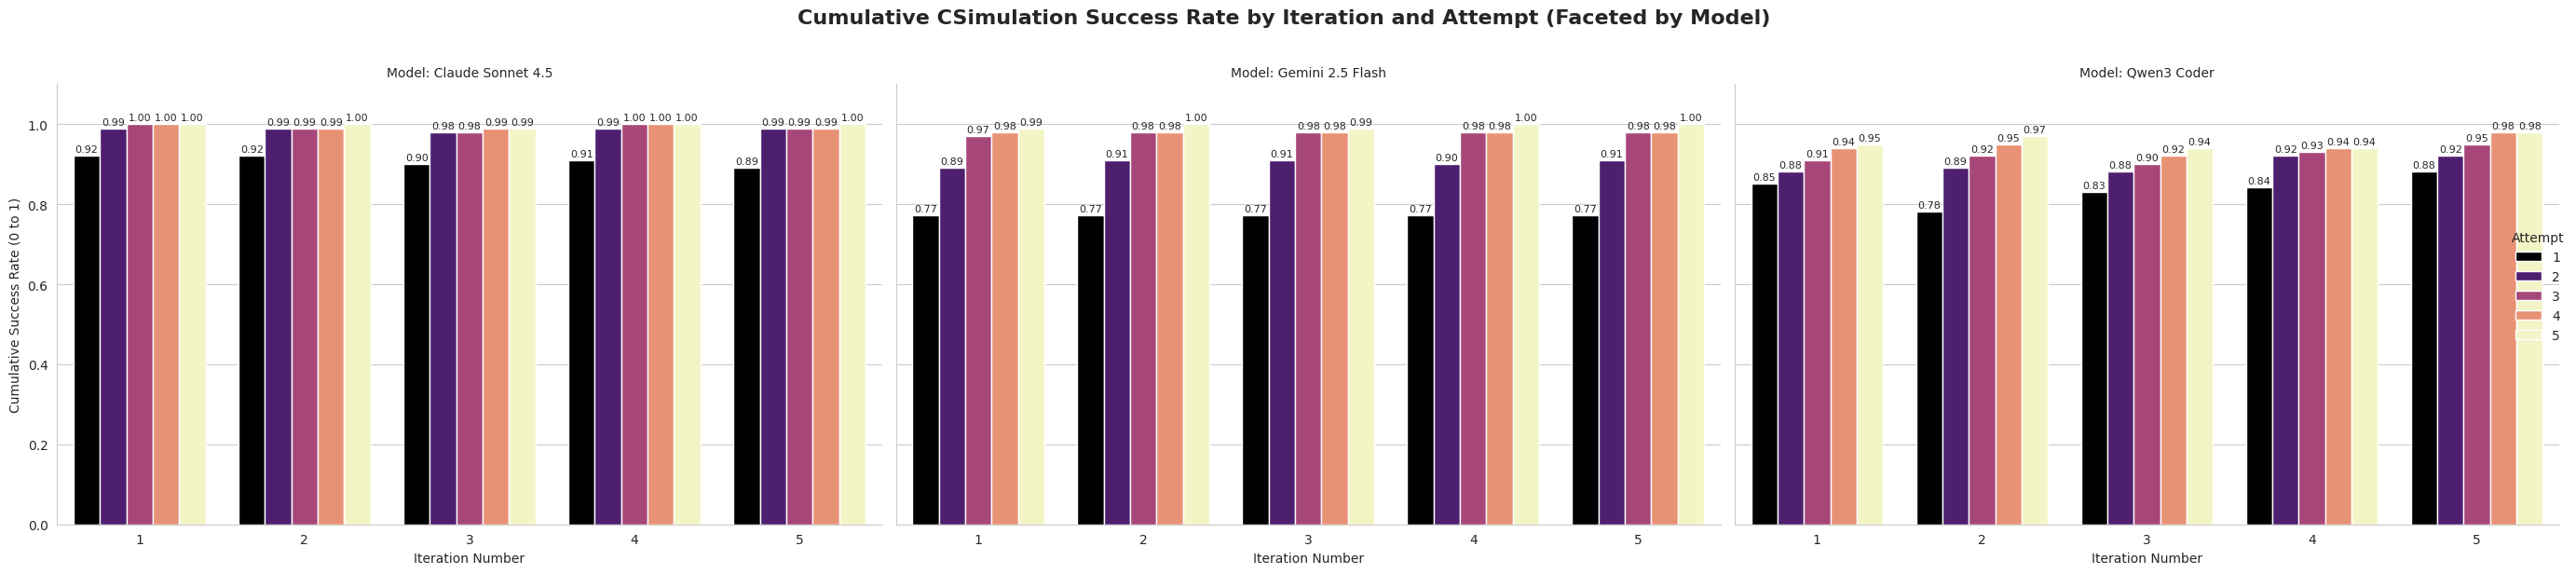

In [51]:
# Set a clean plotting style
sns.set_style("whitegrid")

# Create the faceted bar plot
g = sns.catplot(
    data=full_success_rate_sim, 
    x='run', 
    y='Pass@K Simulation Success Rate', 
    hue='attempt', 
    col='model', # Separate plot for each model
    kind='bar', 
    palette='magma',
    height=6, 
    aspect=1.5 # Adjust aspect ratio
)

# --- Add Labels and Title ---
g.fig.suptitle(
    'Cumulative CSimulation Success Rate by Iteration and Attempt (Faceted by Model)', 
    fontsize=16, 
    fontweight='bold', 
    y=1.02 # Adjust title position
)

# Set common axis labels
g.set_axis_labels("Iteration Number", "Cumulative Success Rate (0 to 1)")
g.set_titles(col_template="Model: {col_name}")
g.legend.set_title("Attempt")

# Set Y-axis limit for a proper rate representation
g.set(ylim=(0, 1.1)) 

# --- Add the actual success rate on top of the bars ---
for ax in g.axes.flat:
    # Iterate through the bars in each subplot
    for p in ax.patches:
        rate = p.get_height()
        # Only annotate if the bar has a non-zero height
        if rate > 0:
             ax.annotate(
                f'{rate:.2f}',  # Format to two decimal places
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', 
                va='center', 
                xytext=(0, 5), # Slight offset above the bar
                textcoords='offset points',
                fontsize=8
            )
            
plt.tight_layout()
# plt.show()

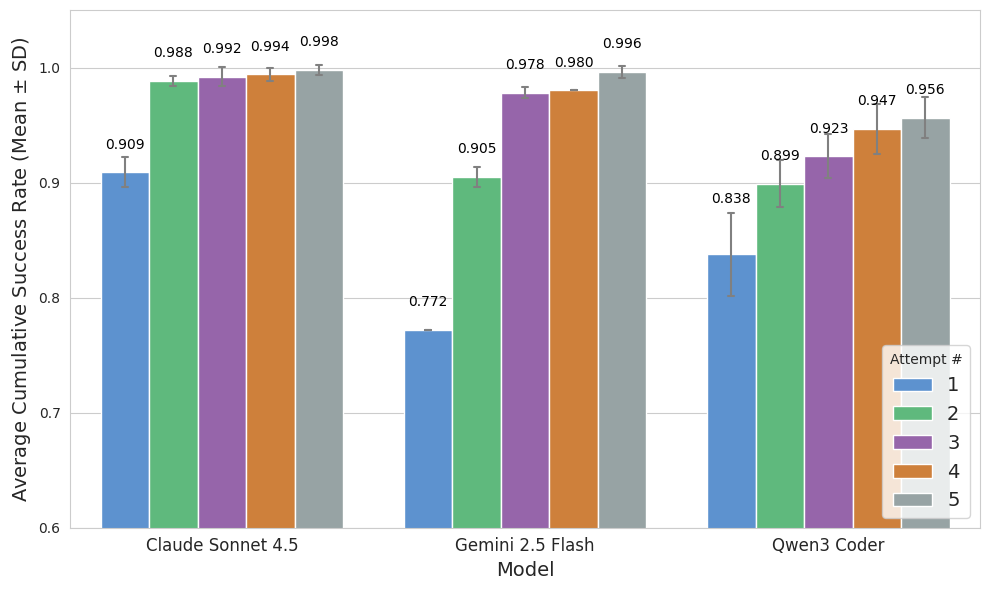

In [52]:
# Set a clean plotting style
sns.set_style("whitegrid")

trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#95A5A6']

plt.figure(figsize=(10, 6))

# Use barplot:
ax = sns.barplot(
    data=full_success_rate_sim, 
    x='model', 
    y='Pass@K Simulation Success Rate', 
    hue='attempt',           # Key: Plots separate, grouped bars for each model
    errorbar='sd',         # Key: Calculates and displays the Standard Deviation (whiskers)
    err_kws={'color': 'gray', 'linewidth': 1.5},
    capsize=0.1,           # Adds small caps to the whiskers for clarity
    palette=trial_colors      # Use a distinct color palette
)


for p in ax.patches:
    # Get the mean value (height of the bar)
    mean_value = p.get_height()
    
    # Only annotate if the bar has a non-zero height
    if mean_value > 0:
        if mean_value > .8 and mean_value < .84:
            ax.annotate(
                f'{mean_value:.3f}',  # Format the mean to three decimal places
                # Position the text: centered horizontally, slightly above the bar
                (p.get_x() + p.get_width() / 2., mean_value), 
                ha='center', 
                va='center', 
                xytext=(0, 40), # Slight offset above the bar (increased from 5 to 10 for better visibility above the whisker cap)
                textcoords='offset points',
                fontsize=10,
                color='black'
            )
        else:
            ax.annotate(
                f'{mean_value:.3f}',  # Format the mean to three decimal places
                # Position the text: centered horizontally, slightly above the bar
                (p.get_x() + p.get_width() / 2., mean_value), 
                ha='center', 
                va='center', 
                xytext=(0, 20), # Slight offset above the bar (increased from 5 to 10 for better visibility above the whisker cap)
                textcoords='offset points',
                fontsize=10,
                color='black'   
            )

# --- Add Labels and Title ---
# plt.title(
#     'Average Success Rate Per Attempt (CSimulation)', 
#     fontsize=16, 
#     fontweight='bold'
# )
plt.xticks(fontsize=12)
plt.xlabel('Model', fontsize=14)
plt.ylabel('Average Cumulative Success Rate (Mean $\pm$ SD)', fontsize=14)
plt.legend(title='Attempt #', loc='lower right', fontsize=14)

# Set Y-axis limit for a proper rate representation
plt.ylim(.6, 1.05) 

plt.tight_layout()
plt.savefig("average_success_by_model.pdf")
plt.show()

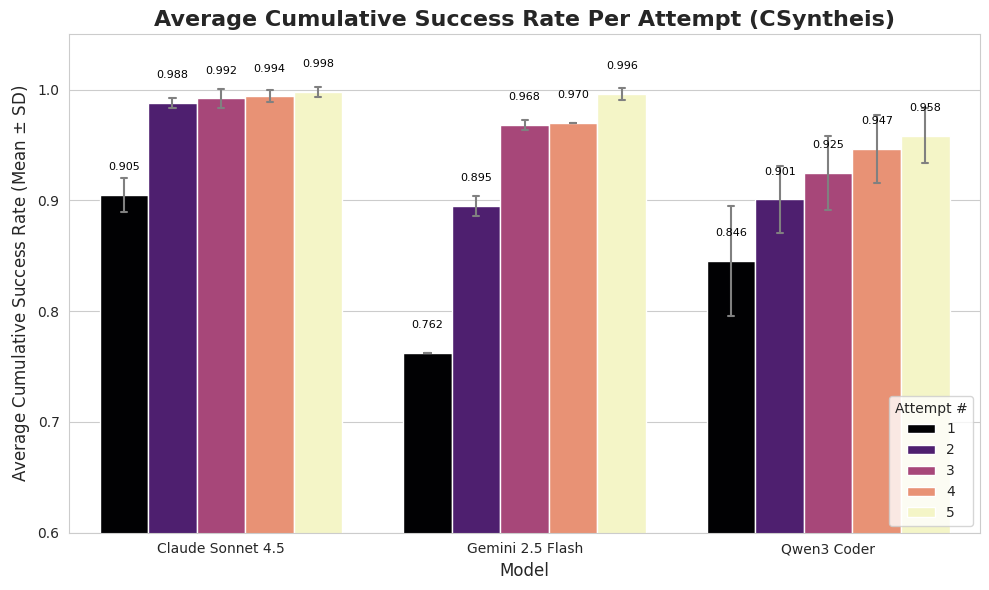

In [53]:
# Set a clean plotting style
sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))

# Use barplot:
ax = sns.barplot(
    data=full_success_rate_synth, 
    x='model', 
    y='Pass@K Synthesis Success Rate', 
    hue='attempt',           # Key: Plots separate, grouped bars for each model
    errorbar='sd',         # Key: Calculates and displays the Standard Deviation (whiskers)
    err_kws={'color': 'gray', 'linewidth': 1.5},
    capsize=0.1,           # Adds small caps to the whiskers for clarity
    palette='magma'      # Use a distinct color palette
)

for p in ax.patches:
    # Get the mean value (height of the bar)
    mean_value = p.get_height()
    
    # Only annotate if the bar has a non-zero height
    if mean_value > 0:
        ax.annotate(
            f'{mean_value:.3f}',  # Format the mean to three decimal places
            # Position the text: centered horizontally, slightly above the bar
            (p.get_x() + p.get_width() / 2., mean_value), 
            ha='center', 
            va='center', 
            xytext=(0, 20), # Slight offset above the bar (increased from 5 to 10 for better visibility above the whisker cap)
            textcoords='offset points',
            fontsize=8,
            color='black'
        )

# --- Add Labels and Title ---
plt.title(
    'Average Cumulative Success Rate Per Attempt (CSyntheis)', 
    fontsize=16, 
    fontweight='bold'
)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Average Cumulative Success Rate (Mean $\pm$ SD)', fontsize=12)
plt.legend(title='Attempt #', loc='lower right')

# Set Y-axis limit for a proper rate representation
plt.ylim(.6, 1.05) 

plt.tight_layout()
plt.show()

               model  attempt  anyrun_cummax_csim
0  Claude Sonnet 4.5        1            0.920792
1  Claude Sonnet 4.5        2            1.000000
2  Claude Sonnet 4.5        3            1.000000
3  Claude Sonnet 4.5        4            1.000000
4  Claude Sonnet 4.5        5            1.000000


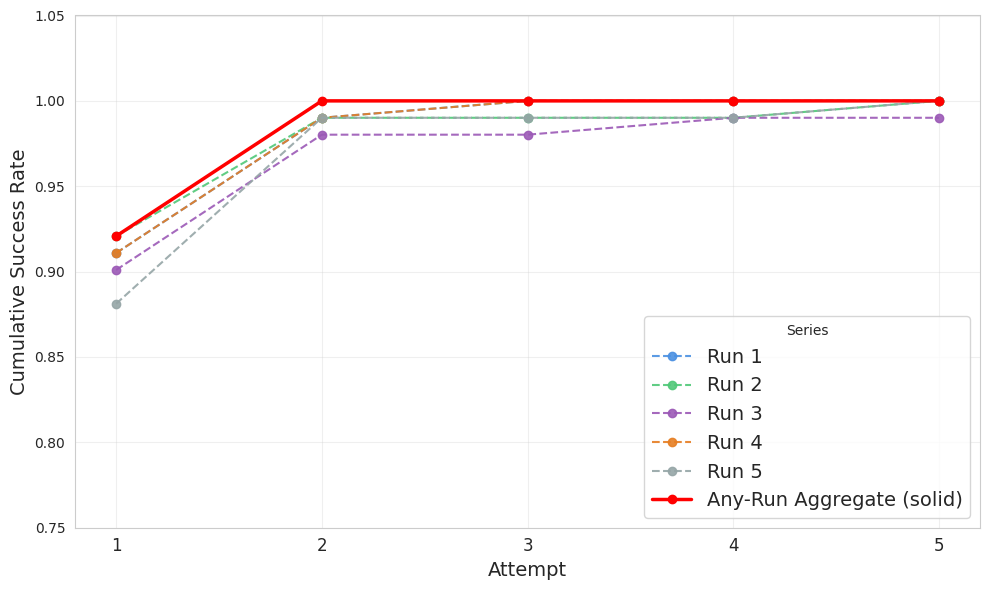

              model  attempt  anyrun_cummax_csim
5  Gemini 2.5 Flash        1            0.772277
6  Gemini 2.5 Flash        2            0.930693
7  Gemini 2.5 Flash        3            0.980198
8  Gemini 2.5 Flash        4            0.980198
9  Gemini 2.5 Flash        5            1.000000


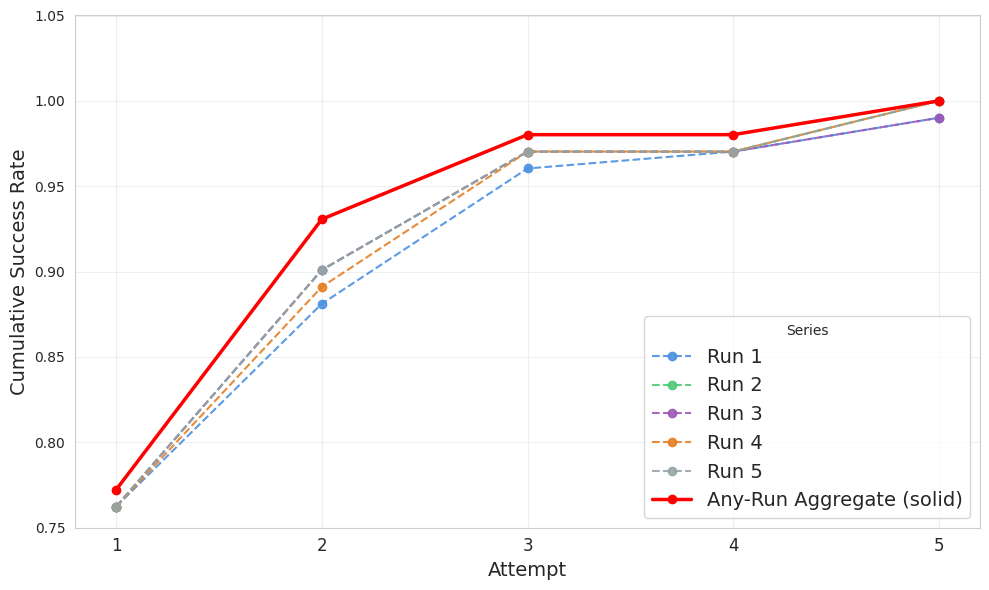

          model  attempt  anyrun_cummax_csim
10  Qwen3 Coder        1            0.950495
11  Qwen3 Coder        2            1.000000
12  Qwen3 Coder        3            1.000000
13  Qwen3 Coder        4            1.000000
14  Qwen3 Coder        5            1.000000


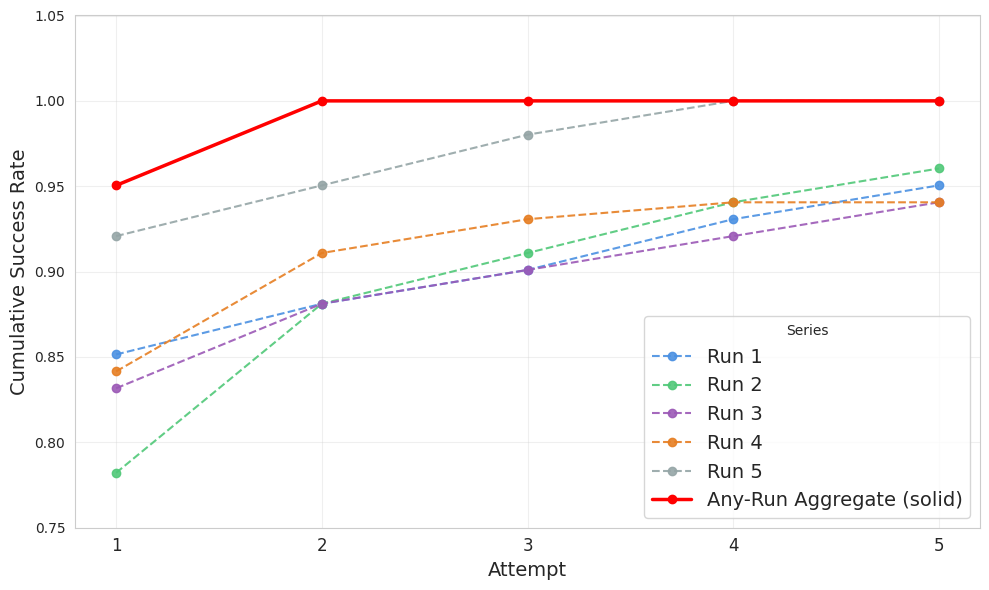

In [54]:
# Making the graph with the attempts separated and with dashed LInes and then the Cummulative on top
# Distinct colors for each trial using different colormaps
trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#95A5A6']


df_norag['model'] = df_norag['model'].map(model_names)

run1 = avg_by_attempt(df_norag, 1)
run2 = avg_by_attempt(df_norag, 2)
run3 = avg_by_attempt(df_norag, 3)
run4 = avg_by_attempt(df_norag, 4)
run5 = avg_by_attempt(df_norag, 5)

pass_at_k_anyrun_sim['model'] = pass_at_k_anyrun_sim['model'].map(model_names)
pass_at_k_anyrun_synth['model'] = pass_at_k_anyrun_synth['model'].map(model_names)
passAt5Sim = pass_at_k_anyrun_sim
passAt5Synth = pass_at_k_anyrun_synth

models = df_norag['model'].unique()

for model in models:
    plt.figure(figsize=(10,6))
    # plot each run (dashed)
    runs_list = [run1, run2, run3, run4, run5]
    for i, run_df in enumerate(runs_list, start=1):
        dfm = run_df[run_df['model'] == model]
        if dfm.empty:
            continue
        plt.plot(
            dfm['attempt'],
            dfm['avg_csynth_success'],
            label=f'Run {i}',
            linestyle='--',
            color=trial_colors[i-1],
            marker='o',
            linewidth=1.5,
            alpha=0.9
        )
    # plot aggregate any-run pass@k (solid)
    agg = passAt5Sim[passAt5Sim['model'] == model]
    print(agg)
    if not agg.empty:
        plt.plot(
            agg['attempt'],
            agg['anyrun_cummax_csynth'] if 'anyrun_cummax_csynth' in agg.columns else agg.iloc[:,2],
            label='Any-Run Aggregate (solid)',
            linestyle='-',
            color='red',
            marker='o',
            linewidth=2.5
        )
    
    # plt.title(f'{model} — Avg Cumulative CSynth Success by Attempt\n')
    plt.xlabel('Attempt', fontsize=14)
    plt.ylabel('Cumulative Success Rate', fontsize=14)
    plt.xticks(np.arange(1, 6), fontsize=12)
    plt.ylim(0.75, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(title='Series', loc='lower right', fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{model}_avg_cumul_csynth.pdf")
    plt.show()

                model  attempt  Average Metric
0   Claude Sonnet 4.5        1           430.0
1   Claude Sonnet 4.5        2           417.0
2   Claude Sonnet 4.5        3           679.0
3   Claude Sonnet 4.5        4           679.0
4   Claude Sonnet 4.5        5           417.0
5    Gemini 2.5 Flash        1          1140.0
6    Gemini 2.5 Flash        2           684.0
7    Gemini 2.5 Flash        3           417.0
8    Gemini 2.5 Flash        4           417.0
9    Gemini 2.5 Flash        5           417.0
10        Qwen3 Coder        1           417.0
11        Qwen3 Coder        2           417.0
12        Qwen3 Coder        3           417.0
13        Qwen3 Coder        4           417.0
14        Qwen3 Coder        5           417.0


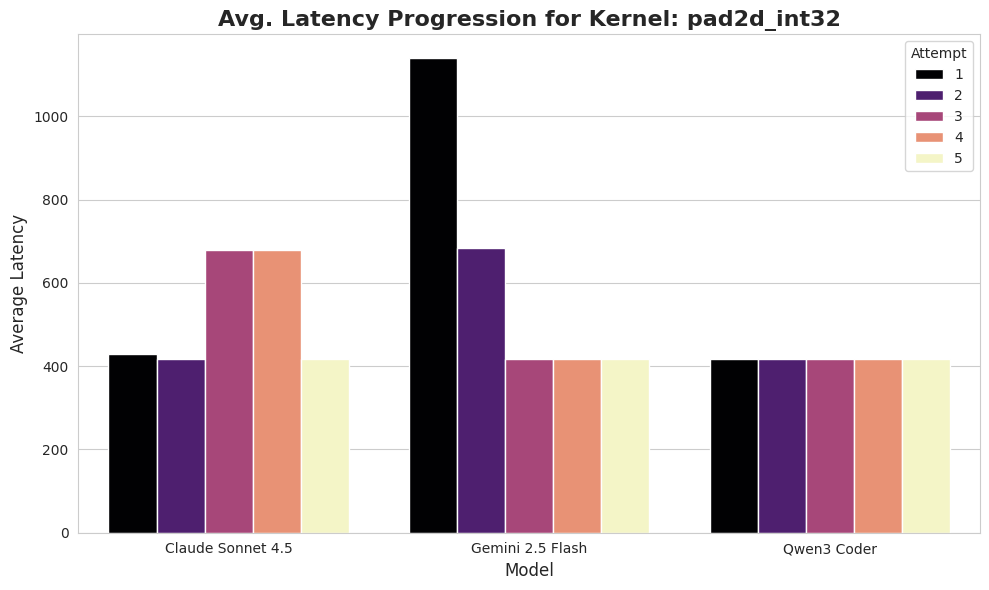

In [55]:
# Looking at the latencies on 10 different kernels

#Just the rows with these kernels Elementwise Operation: 
kernels = {'abs_int8', 'relu_bfloat16', 'conv2d_int32', 'vectormatrix_mult_int32', 'argmin_bfloat16', 'mse_loss_bfloat16', 
           'euclidean_dist_bfloat16', 'bitwiseand_uint8', 'cast_bfloat16_to_int8', 'pad2d_int32'}

df_filtered = df_norag[df_norag['kernel'].isin(kernels)]

df_filtered = df_filtered[['model','kernel','run','attempt', 'latency', 'bram', 'ff', 'lut', 'dsp', 'csynth_success']]
def plot_kernel_bar_progression_mean_only(df, target_kernel, metric_col):
    """
    Filters data for a target kernel, aggregates metrics across iterations,
    and plots the mean metric value as a bar chart, grouped by model and attempt,
    with custom annotations showing ONLY the Mean.
    """
    # 1. Filter for the specific kernel
    df_kernel = df[df['kernel'] == target_kernel].copy()

    if df_kernel.empty:
        print(f"Error: Kernel '{target_kernel}' not found in the data.")
        return

    # 2. Aggregate Data: Calculate ONLY the Mean across all 5 iterations
    # --- CHANGE: 'std' is removed from .agg() ---
    agg_df = df_kernel.groupby(['model', 'attempt'])[metric_col].agg(['min']).reset_index()
    agg_df.rename(
        columns={'min': 'Average Metric'},
        inplace=True
    )
    print(agg_df)
    
    # --- 3. Plotting ---
    sns.set_style("whitegrid")
    plt.figure(figsize=(10, 6))

    # Plot the MEAN bar height (errorbar=None is not strictly needed but harmless)
    ax = sns.barplot(
        data=agg_df, 
        x='model', 
        y='Average Metric', 
        hue='attempt',
        errorbar=None,  # No error bars are calculated or drawn
        palette='magma'
    )

    # 5. Final Labels and Title
    y_label_name = metric_col.replace('_', ' ').title()
    plt.title(
        f'Avg. {y_label_name} Progression for Kernel: {target_kernel}', 
        fontsize=16, 
        fontweight='bold'
    )
    plt.xlabel('Model', fontsize=12)
    # --- CHANGE: Removed (Mean ± SD) from Y-axis label ---
    plt.ylabel(f'Average {y_label_name}', fontsize=12) 
    plt.legend(title='Attempt', loc='upper right') 

    plt.tight_layout()
    plt.show()


plot_kernel_bar_progression_mean_only(df_filtered, 'pad2d_int32', 'latency')



In [56]:
# --- 1. Map the 'Never Succeeded' value back to a string for the Y-axis ---
# Plotly often handles categorical axes better if the actual values are strings


# --- 3. Find the First Successful Attempt ---
# Filter for successful attempts only
success_df = df_norag[df_norag['synth_success'] == 1]

# Group by the identifiers (model, iteration, kernel) and find the minimum attempt number
first_success_attempt = success_df.groupby(['model', 'iteration', 'kernel'])['attempts'].min().reset_index()

# Rename the column for clarity
first_success_attempt.rename(
    columns={'attempts': 'First Successful Attempt'}, 
    inplace=True
)

# --- 4. Handle Kernels that Never Succeeded ---
# Get all unique model, iteration, and kernel combinations
all_combinations = df_norag[['model', 'iteration', 'kernel']].drop_duplicates()

# Merge the first success data back. Kernels that failed all attempts will get NaN.
# Assuming max attempt is 5, we use 6 to represent 'Never Succeeded'
MAX_ATTEMPTS = df_norag['attempts'].max()
failed_indicator = MAX_ATTEMPTS + 1

final_df = pd.merge(
    all_combinations, 
    first_success_attempt, 
    on=['model', 'iteration', 'kernel'], 
    how='left'
)

# Fill NaN values (failed kernels) with the indicator value (6)
final_df['First Successful Attempt'] = final_df['First Successful Attempt'].fillna(failed_indicator)
final_df['First Successful Attempt'] = final_df['First Successful Attempt'].astype(int)


# --- 5. Create a Sequential Kernel Index for Plotting ---
# This makes the X-axis cleaner than using the string/ID of the kernel
kernel_map = {kernel: i for i, kernel in enumerate(final_df['kernel'].unique(), 1)}
final_df['kernel_index'] = final_df['kernel'].map(kernel_map)

MAX_ATTEMPTS = 5 # Assuming 5 attempts max based on context
failed_indicator = MAX_ATTEMPTS + 1

# Create a mapping dictionary for the y-axis labels
y_label_map = {i: str(i) for i in range(1, MAX_ATTEMPTS + 1)}
y_label_map[failed_indicator] = 'Never Succeeded'

# Apply the map to a new categorical column
final_df['Success_Attempt_Label'] = final_df['First Successful Attempt'].map(y_label_map)


# --- 2. Create the Interactive Plotly Express Figure ---
fig = px.scatter(
    final_df,
    x='kernel_index',           # X-axis: Kernel Index
    y='Success_Attempt_Label',  # Y-axis: Categorical Attempt Label (1, 2, ..., Never Succeeded)
    color='model',              # Use model for color to differentiate dots
    facet_col='model',          # Facet (column) for different models
    facet_row='iteration',      # Facet (row) for different iterations
    title='First Successful Attempt for Each Kernel (Interactive)',
    
    height=1200,
    # 🎯 KEY CHANGE: Define what shows up in the tooltip when you hover
    hover_data={
        'kernel': True,         # Show the actual kernel name (the ID you want to see)
        'model': False,
        'iteration': False,
        'kernel_index': False,  # Hide the index since we show the name
        'Success_Attempt_Label': False,
        'First Successful Attempt': False # Hide the numeric indicator (6)
    }
)

# --- 3. Update Layout and Axes ---
fig.update_xaxes(title_text="Kernel Index")
fig.update_yaxes(title_text="Attempt Number")

# Ensure the y-axis is ordered correctly (Plotly treats strings alphabetically by default)
# We need to explicitly order the categories: 1, 2, 3, 4, 5, Never Succeeded
y_order = [str(i) for i in range(1, MAX_ATTEMPTS + 1)] + ['Never Succeeded']
fig.update_yaxes(categoryorder='array', categoryarray=y_order)


# --- 4. Display the Interactive Plot ---
# In a Jupyter environment, this displays the interactive chart directly.
fig.show()

KeyError: 'synth_success'